# Part II — Mackey-Glass chaotic time-series prediction

DD2437 lab 1, section 4. Owner: Tytus.

**What this notebook does.** Generates the Mackey-Glass series, builds the
time-delay embedding, searches over three-layer perceptron architectures,
evaluates the best and worst on the held-out test block, and then studies how
Gaussian noise and L2 weight decay interact.

**How to read it.** The heavy sweeps are run by the scripts
(`grid_search.py`, `noise_experiments.py`, `model_selection_noise.py`) and
cached as JSON in `results/`. This notebook loads those caches and produces
the tables and figures. Set `RERUN = True` in the setup cell to recompute from
scratch (takes roughly 45 minutes).

The theory behind every choice is in `NOTES.md`; the open decisions the team had
to make are tabulated in `README.md`.

In [1]:
import os, sys, json
sys.path.insert(0, os.path.abspath("."))

import numpy as np
import matplotlib.pyplot as plt

from generate_mackey_glass import mackey_glass
from build_dataset import make_embedding, split_blocks, add_noise_xy, T_START, T_END
from model import build_net, train_torch, mse, predict, get_weights, n_params
import grid_search as G
import noise_experiments as N
import plots as P

RERUN = False          # True = recompute the sweeps instead of loading results/
RESULTS = "results"
os.makedirs(RESULTS, exist_ok=True)
plt.rcParams.update({"figure.dpi": 110, "axes.grid": False})
print("ready")

ready


## 4.1 Data

### The series

The Mackey-Glass delay differential equation

$$\frac{dx}{dt} = \frac{\beta\, x(t-\tau)}{1 + x^{n}(t-\tau)} - \gamma x(t)$$

with $\beta=0.2$, $\gamma=0.1$, $n=10$, $\tau=25$, discretised by Euler with
step 1:

$$x(t+1) = x(t) + \frac{0.2\,x(t-25)}{1 + x^{10}(t-25)} - 0.1\,x(t)$$

starting from $x(0)=1.5$ and $x(t)=0$ for $t<0$.

$\tau=25$ sits well inside the chaotic regime (chaos appears above
$\tau \approx 16.8$). Chaotic means bounded, aperiodic and exponentially
sensitive to initial conditions — so the series never repeats and a model
cannot win by memorising a period. It has to learn the local dynamics. That is
what makes this a benchmark.

It is also **deterministic**: there is no noise in the generator, so on clean
data the irreducible error is exactly zero and every error is the model's own.

length 1600, range [0.102, 1.500]


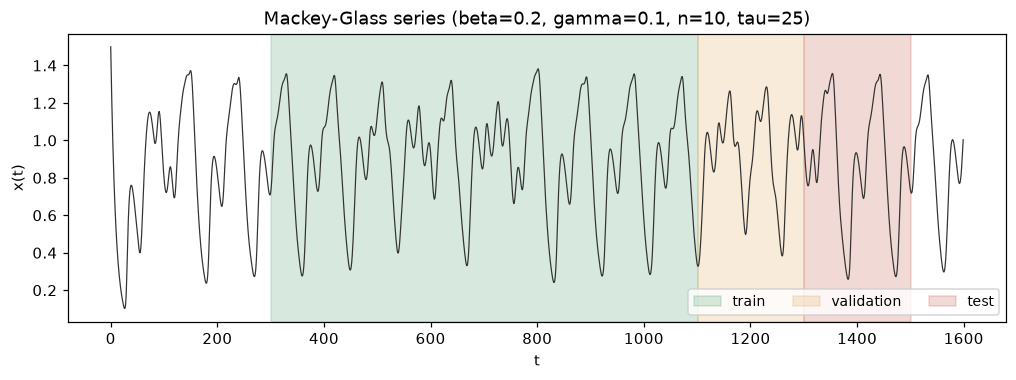

In [2]:
x = mackey_glass(n_points=1600)
print(f"length {len(x)}, range [{x.min():.3f}, {x.max():.3f}]")

fig = P.plot_series(x)
P.save(fig, "01_series.png"); plt.show()

### Time-delay embedding

An MLP is a static map $\mathbb{R}^5 \to \mathbb{R}$ — it has no memory — so the
time structure must be put into the input vector by hand:

$$\text{input}(t) = [x(t{-}20),\, x(t{-}15),\, x(t{-}10),\, x(t{-}5),\, x(t)],
\qquad \text{target}(t) = x(t{+}5)$$

**Takens' embedding theorem** is the justification: for a deterministic
dynamical system, a delay vector of dimension $m > 2d$ (with $d$ the attractor
dimension) is a diffeomorphic embedding of the attractor. Once the delay vector
identifies the state, $x(t{+}5)$ is a *deterministic function* of it, and the
problem reduces to ordinary regression — where the MLP's universal
approximation property applies.

### Why the split must be consecutive blocks

`input(t)` and `input(t+1)` share four of their five components. A random
shuffle would put near-duplicate samples in both training and validation, so
validation error would measure interpolation between near-copies rather than
generalisation — optimistically biased, often by an order of magnitude, and
every model-selection decision built on it would be worthless.

Blocks also match the deployment story: fit on the past, predict the future.

**Our split: 800 / 200 / 200.** Only the 200-sample test block is fixed by the
lab.

In [3]:
X, y = make_embedding(x)
train, val, test = split_blocks(X, y, n_train=800, n_val=200, n_test=200)
(Xtr, ytr), (Xval, yval), (Xte, yte) = train, val, test

t_all  = np.arange(T_START, T_END + 1)
t_test = t_all[-len(yte):]

for name, (Xs, ys) in zip(("train", "val", "test"), (train, val, test)):
    print(f"{name:5s} X={Xs.shape}  y={ys.shape}  target range [{ys.min():.3f}, {ys.max():.3f}]")
print(f"\nvar(y_train) = {ytr.var():.5f}   <- the scale every MSE below is measured against")

train X=(800, 5)  y=(800,)  target range [0.241, 1.382]
val   X=(200, 5)  y=(200,)  target range [0.383, 1.286]
test  X=(200, 5)  y=(200,)  target range [0.258, 1.358]

var(y_train) = 0.08581   <- the scale every MSE below is measured against


## 4.2 Network configuration

$$5 \to n_{h1}\ (\tanh) \to n_{h2}\ (\tanh) \to 1\ (\text{linear})$$

A "three-layer perceptron" counts **weight layers**, so there are two hidden
layers.

| choice | why |
|---|---|
| `tanh` hidden units | sigmoidal, as required; exactly part I's $\varphi(x)=\frac{2}{1+e^{-x}}-1 = \tanh(x/2)$; zero-centred, so better conditioned than the logistic sigmoid |
| **linear** output | targets lie in $[0.24, 1.38]$ — a logistic sigmoid is bounded in $(0,1)$ and literally could not reach 1.38; a saturated sigmoid also has $\varphi' \approx 0$, so backprop multiplies the error by ~0 and upstream layers stop learning. Linear output has derivative 1 and makes $\delta^{(o)} = (o-t)$ exactly |
| full-batch | the lab asks for batch backprop: one weight update per epoch, over all 800 patterns |
| Adam, $\eta=0.01$ | the lab warns a bad learning rate gives premature convergence or endless runs; Adam adapts a per-parameter step from the gradient's first and second moments |
| no input standardisation | measured, not assumed: inputs already sit in $[0.2, 1.4]$, and standardising moved the validation error by less than the seed-to-seed spread |

**Weight decay.** The optimised loss is $\text{MSE}(w) + \lambda \sum_i w_i^2$,
so the gradient gains $2\lambda w_i$ and the update becomes

$$w_i \leftarrow (1 - 2\eta\lambda)\, w_i - \eta \frac{\partial \text{MSE}}{\partial w_i}$$

Every weight shrinks multiplicatively on every step and survives only if the
data keeps pushing it back. Biases are **not** penalised: penalising a bias only
shifts the function vertically, it does not smooth it.

Everything reported below is **plain MSE**, never the penalised loss — otherwise
models trained with different $\lambda$ would not be comparable.

parameters      : 73
epochs run      : 14661   (ceiling 60000)
best epoch      : 11660
train / val / test MSE: 3.959e-04 / 3.413e-04 / 4.612e-04


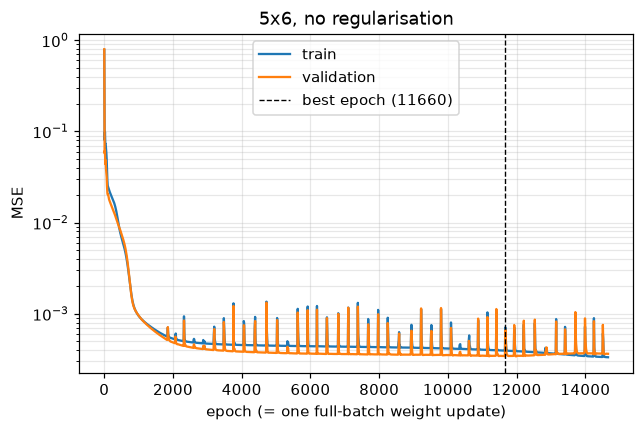

In [4]:
# one run, recording the learning curve
net = build_net(5, 6, seed=0)
info = train_torch(net, Xtr, ytr, Xval, yval, lam=0.0, lr=0.01,
                   epochs=60000, patience=3000, record_history=True)

print(f"parameters      : {n_params(5, 6)}")
print(f"epochs run      : {info['epochs_run']}   (ceiling 60000)")
print(f"best epoch      : {info['best_epoch']}")
print(f"train / val / test MSE: {mse(net, Xtr, ytr):.3e} / "
      f"{mse(net, Xval, yval):.3e} / {mse(net, Xte, yte):.3e}")

fig = P.plot_learning_curves(info["history"], "5x6, no regularisation",
                             best_epoch=info["best_epoch"])
P.save(fig, "02_learning_curve.png"); plt.show()

### Early stopping, and the trap we actually hit

Early stopping watches validation MSE, keeps the weights from the best epoch,
and stops after `patience` epochs without improvement. It regularises because
weights start small (the near-linear region of `tanh`, so the network begins as
an almost-linear model) and grow as training proceeds — growing weights mean
growing *effective* capacity. Stopping early caps that capacity without
changing the architecture. For a linear model this is provably close to L2
regularisation with $\lambda \propto 1/(\eta \cdot \text{epochs})$.

The lab warns about early stopping firing *prematurely*. We hit a subtler
version of the same trap in the opposite direction. With a 10 000-epoch ceiling
the grid below ranked **convergence speed, not capacity**: the small
architectures had simply not finished converging. `3x2` kept improving until
roughly 48 000 epochs and then nearly caught `5x6`, while `5x6` was done at
about 8 400 and never moved again. Small networks converge far more slowly —
fewer parameters means a narrower, more ill-conditioned loss surface with less
gradient redundancy to exploit.

The fix is a generous ceiling (60 000) with `patience=3000`, so **every**
architecture reaches its own plateau before it is judged. That is what the lab
means by letting early stopping control the duration of learning.

## 4.3 task 2 — architecture grid search

Cartesian product $n_{h1} \in \{3,4,5\} \times n_{h2} \in \{2,4,6\}$, each
trained with **10 random seeds**.

Repeats are not optional bookkeeping. Random initialisation makes every run a
draw from a distribution over solutions, so a single run of `4x6` beating a
single run of `5x4` tells you nothing. The lab asks for the first *and* second
moment, and the **std across seeds is the answer to "how robust is this
architecture to random weight initialisation?"**

In [5]:
if RERUN:
    runs = G.grid_search(train, val, test)
    rows = G.summarise(runs)
    best, worst = G.pick_best_worst(rows)
    json.dump({"runs": runs, "rows": rows, "best": best, "worst": worst},
              open(f"{RESULTS}/grid_search.json", "w"), indent=1)
else:
    d = json.load(open(f"{RESULTS}/grid_search.json"))
    runs, rows, best, worst = d["runs"], d["rows"], d["best"], d["worst"]

print(G.format_table(rows, highlight=((best["nh1"], best["nh2"]),
                                      (worst["nh1"], worst["nh2"]))))
print(f"\nmost suitable : {best['nh1']}x{best['nh2']}  "
      f"val {best['val_mse_mean']:.3e} +/- {best['val_mse_std']:.1e}")
print(f"least suitable: {worst['nh1']}x{worst['nh2']}  "
      f"val {worst['val_mse_mean']:.3e} +/- {worst['val_mse_std']:.1e}")

  arch  par              train MSE                val MSE               test MSE   best ep
------------------------------------------------------------------------------------------
5x6  *   73  3.74e-04+/-4.8e-05     3.60e-04+/-3.3e-05     4.42e-04+/-3.3e-05        13590
3x6      49  4.00e-04+/-3.7e-05     3.74e-04+/-2.9e-05     4.36e-04+/-2.7e-05        20572
5x4      59  3.83e-04+/-3.3e-05     3.75e-04+/-4.7e-05     4.20e-04+/-4.3e-05        19219
4x6      61  3.82e-04+/-2.5e-05     3.88e-04+/-3.1e-05     4.41e-04+/-3.7e-05        13986
4x4      49  3.99e-04+/-3.0e-05     4.01e-04+/-4.7e-05     4.28e-04+/-3.6e-05        19387
5x2      45  4.26e-04+/-3.6e-05     4.08e-04+/-5.2e-05     4.46e-04+/-4.1e-05        25477
4x2      37  4.46e-04+/-3.5e-05     4.09e-04+/-5.5e-05     4.51e-04+/-2.8e-05        33848
3x2      29  4.71e-04+/-2.0e-05     4.30e-04+/-3.9e-05     4.78e-04+/-1.3e-05        41962
3x4  *   39  4.53e-04+/-3.5e-05     4.38e-04+/-5.3e-05     4.57e-04+/-3.5e-05        14791

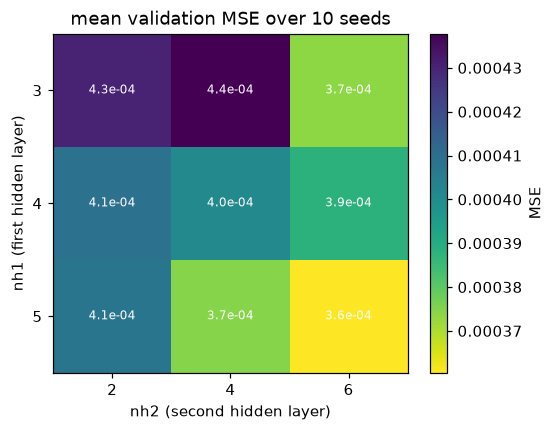

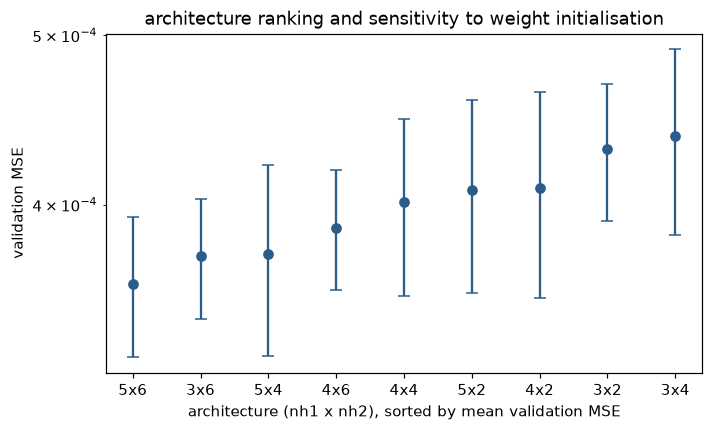

In [6]:
fig = P.plot_grid_heatmap(rows, "val_mse_mean", "mean validation MSE over 10 seeds")
P.save(fig, "03_grid_heatmap.png"); plt.show()

fig = P.plot_arch_spread(rows)
P.save(fig, "04_arch_spread.png"); plt.show()

In [7]:
# robustness to initialisation, stated as a relative spread
print(f"{'arch':>6} {'val mean':>11} {'val std':>11} {'std/mean':>9}")
print("-" * 40)
for r in sorted(rows, key=lambda q: q["val_mse_mean"]):
    rel = r["val_mse_std"] / r["val_mse_mean"]
    print(f"{r['nh1']}x{r['nh2']:<4} {r['val_mse_mean']:>11.3e} "
          f"{r['val_mse_std']:>11.3e} {rel:>8.1%}")

  arch    val mean     val std  std/mean
----------------------------------------
5x6      3.605e-04   3.331e-05     9.2%
3x6      3.737e-04   2.940e-05     7.9%
5x4      3.747e-04   4.704e-05    12.6%
4x6      3.881e-04   3.083e-05     7.9%
4x4      4.015e-04   4.662e-05    11.6%
5x2      4.076e-04   5.164e-05    12.7%
4x2      4.089e-04   5.493e-05    13.4%
3x2      4.302e-04   3.889e-05     9.0%
3x4      4.378e-04   5.321e-05    12.2%


### Is the ranking real?

The lab's footnote waives a formal statistical test, but with 10 seeds per
architecture a Welch t-test costs nothing and keeps the conclusion honest —
otherwise "most" and "least suitable" are just the two ends of a noisy list.

In [8]:
from scipy import stats

def val_samples(a, b):
    return np.array([r["val_mse"] for r in runs if (r["nh1"], r["nh2"]) == (a, b)])

ref = val_samples(best["nh1"], best["nh2"])
print(f"{'arch':>6} {'par':>4} {'val mean':>11} {'std/mean':>9} {'t vs best':>10} {'p':>8} {'best ep':>9}")
print("-" * 62)
for r in sorted(rows, key=lambda q: q["val_mse_mean"]):
    a = val_samples(r["nh1"], r["nh2"])
    t, p = stats.ttest_ind(a, ref, equal_var=False)
    print(f"{r['nh1']}x{r['nh2']:<4} {r['n_params']:>4} {r['val_mse_mean']:>11.3e} "
          f"{r['val_mse_std'] / r['val_mse_mean']:>8.1%} {t:>10.2f} {p:>8.4f} "
          f"{r['best_epoch_mean']:>9.0f}")

# the two worst: is the "least suitable" label even meaningful?
worst_two = sorted(rows, key=lambda q: -q["val_mse_mean"])[:2]
a = val_samples(worst_two[0]["nh1"], worst_two[0]["nh2"])
b = val_samples(worst_two[1]["nh1"], worst_two[1]["nh2"])
t, p = stats.ttest_ind(a, b, equal_var=False)
print(f"\n{worst_two[0]['nh1']}x{worst_two[0]['nh2']} vs "
      f"{worst_two[1]['nh1']}x{worst_two[1]['nh2']} (the two worst): "
      f"t={t:.2f}, p={p:.3f} -> "
      f"{'a real difference' if p < 0.05 else 'NOT distinguishable'}")

# capacity vs convergence time
par = np.array([r["n_params"] for r in rows])
ep  = np.array([r["best_epoch_mean"] for r in rows])
print(f"\ncorr(n_params, mean best epoch) = {np.corrcoef(par, ep)[0, 1]:.3f}")
print(f"convergence spans {ep.min():.0f} to {ep.max():.0f} epochs "
      f"({ep.max() / ep.min():.1f}x) -- SMALLER nets take LONGER")

  arch  par    val mean  std/mean  t vs best        p   best ep
--------------------------------------------------------------
5x6      73   3.605e-04     9.2%       0.00   1.0000     13590
3x6      49   3.737e-04     7.9%       0.94   0.3599     20572
5x4      59   3.747e-04    12.6%       0.78   0.4479     19219
4x6      61   3.881e-04     7.9%       1.92   0.0705     13986
4x4      49   4.015e-04    11.6%       2.26   0.0376     19387
5x2      45   4.076e-04    12.7%       2.43   0.0279     25477
4x2      37   4.089e-04    13.4%       2.38   0.0310     33848
3x2      29   4.302e-04     9.0%       4.31   0.0004     41962
3x4      39   4.378e-04    12.2%       3.89   0.0014     14791

3x4 vs 3x2 (the two worst): t=0.36, p=0.722 -> NOT distinguishable

corr(n_params, mean best epoch) = -0.767
convergence spans 13590 to 41962 epochs (3.1x) -- SMALLER nets take LONGER


Two things to carry into the report:

- The best-vs-worst gap is statistically real, but the **two worst are not
  distinguishable from each other**, so "least suitable" is a tie and should be
  reported as one. Several middle architectures are also indistinguishable from
  the winner — notably `3x6` with 49 parameters matches `5x6` with 73.
- `corr(n_params, best epoch)` is strongly **negative**: smaller networks need
  *more* epochs. This is the quantitative version of the convergence trap above,
  and it is why a fixed epoch budget would have ranked speed instead of capacity.

## 4.3 task 3 — test performance of the two selected architectures

The test block is read **now**, for the first time, after every decision is
made. Selecting on test error would turn it into just another training signal
and destroy its role as an unbiased generalisation estimate.

most suitable 5x6          train 3.959e-04  val 3.413e-04  test 4.612e-04  (stopped at epoch 14661)


least suitable 3x4         train 4.405e-04  val 4.046e-04  test 4.346e-04  (stopped at epoch 23691)


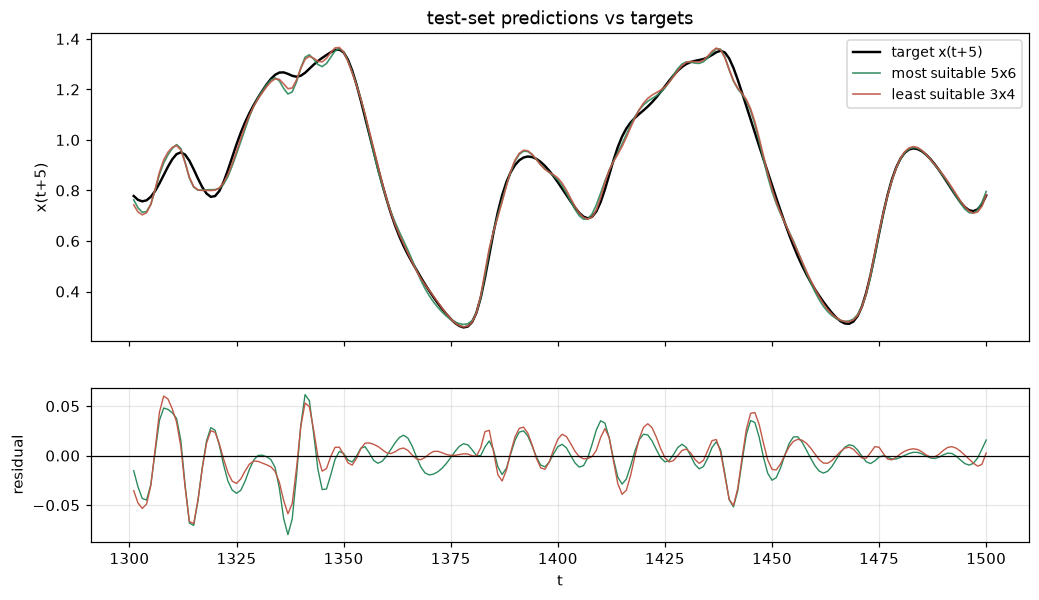

In [9]:
# retrain both architectures and keep the nets for plotting
sel = [(f"most suitable {best['nh1']}x{best['nh2']}", best["nh1"], best["nh2"]),
       (f"least suitable {worst['nh1']}x{worst['nh2']}", worst["nh1"], worst["nh2"])]

nets, labels = [], []
for label, nh1, nh2 in sel:
    r = G.run_config(nh1, nh2, train, val, test, seed=0, return_net=True)
    nets.append(r["net"]); labels.append(label)
    print(f"{label:26s} train {r['train_mse']:.3e}  val {r['val_mse']:.3e}  "
          f"test {r['test_mse']:.3e}  (stopped at epoch {r['epochs_run']})")

fig = P.plot_test_predictions(nets, Xte, yte, t_test, labels)
P.save(fig, "05_test_predictions.png"); plt.show()

## 4.3 task 4 — noise and weight decay

Fixed by the lab: noise $\sigma \in \{0.05, 0.15\}$ on the training data,
$n_{h1}$ fixed to the winner above, $n_{h2} \in \{3, 6, 9\}$, L2 weight decay
with constant $\lambda$, and **no early stopping**.

> The PDF prints `nh2 = 3, 6, 9 6` — the trailing 6 is a **footnote marker**,
> not a number. The grid is 3, 6, 9, consistent with section 4.2's "max 9 nodes
> per hidden layer". No TA query needed.

**Two stated choices.**

1. Noise goes on the **training block only**; validation and test stay clean.
   That is the literal reading of "add noise to training data", and it is the
   informative one: a noisy validation set carries an irreducible floor of
   $\sigma^2$ (0.0225 at $\sigma=0.15$) — about *fifty times* larger than the
   model differences we are trying to measure, which it would completely swamp.
   With a clean validation set, validation MSE directly measures how much of the
   **true dynamics** each model recovered from corrupted observations.
2. Noise corrupts inputs and targets together: in the measurement
   interpretation the whole observed series is noisy, and the lagged inputs are
   just earlier observations of that same series.

**Why early stopping is dropped.** Early stopping and weight decay are both
regularisers competing for the same job. Keeping both would confound them — you
could not tell whether a good result came from $\lambda$ or from stopping early.
With one fixed epoch budget for every run, $\lambda$ is the only variable.

We also report training error against **clean** targets alongside the noisy
ones. Training MSE on noisy targets bottoms out near $\sigma^2$; pushing much
below that means the network is memorising the noise realisation, which shows up
as *rising* clean error. Having both columns makes memorisation visible.

In [10]:
NH1 = best["nh1"]

if RERUN:
    nruns = N.sweep(NH1, train, val, test)
    nrows = N.summarise(nruns)
    dump = [{k: (v.tolist() if isinstance(v, np.ndarray) else v) for k, v in r.items()}
            for r in nruns]
    json.dump(dump, open(f"{RESULTS}/noise_runs.json", "w"))
    json.dump(nrows, open(f"{RESULTS}/noise_rows.json", "w"), indent=1)
else:
    nruns = json.load(open(f"{RESULTS}/noise_runs.json"))
    nrows = json.load(open(f"{RESULTS}/noise_rows.json"))

print(N.format_table(nrows))

 sigma   arch   lambda  train(noisy)  train(clean)       val MSE      test MSE   std(w)   max|w|
------------------------------------------------------------------------------------------------
  0.00 5x3           0     3.700e-04     3.700e-04     4.144e-04     4.115e-04    1.022    3.195
  0.00 5x3       1e-05     4.462e-04     4.462e-04     4.254e-04     4.319e-04    0.661    1.987
  0.00 5x3      0.0001     7.010e-04     7.010e-04     6.960e-04     6.657e-04    0.527    1.762
  0.00 5x3       0.001     2.711e-03     2.711e-03     2.781e-03     2.997e-03    0.387    1.152
  0.00 5x3        0.01     1.803e-02     1.803e-02     1.432e-02     2.109e-02    0.244    0.547
  0.00 5x3         0.1     8.581e-02     8.581e-02     5.151e-02     9.904e-02    0.000    0.001

  0.00 5x6           0     3.017e-04     3.017e-04     3.775e-04     4.295e-04    1.122    4.008
  0.00 5x6       1e-05     4.438e-04     4.438e-04     4.007e-04     4.332e-04    0.553    2.055
  0.00 5x6      0.0001     6.

In [11]:
print("best lambda per (sigma, nh2), chosen on validation MSE:\n")
print(f"{'sigma':>6} {'arch':>6} {'lambda*':>9} {'val MSE':>12}")
print("-" * 36)
for (sigma, nh2), r in sorted(N.best_lambda_per_config(nrows).items()):
    print(f"{sigma:>6.2f} {NH1}x{nh2:<4} {r['lam']:>9g} {r['val_mse_mean']:>12.3e}")

best lambda per (sigma, nh2), chosen on validation MSE:

 sigma   arch   lambda*      val MSE
------------------------------------
  0.00 5x3            0    4.144e-04
  0.00 5x6            0    3.775e-04
  0.00 5x9            0    3.867e-04
  0.05 5x3        1e-05    2.190e-03
  0.05 5x6        1e-05    2.218e-03
  0.05 5x9       0.0001    2.239e-03
  0.15 5x3       0.0001    8.480e-03
  0.15 5x6       0.0001    8.598e-03
  0.15 5x9       0.0001    8.875e-03


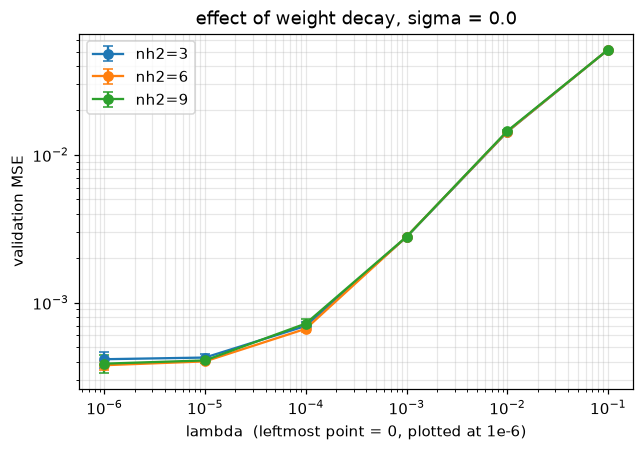

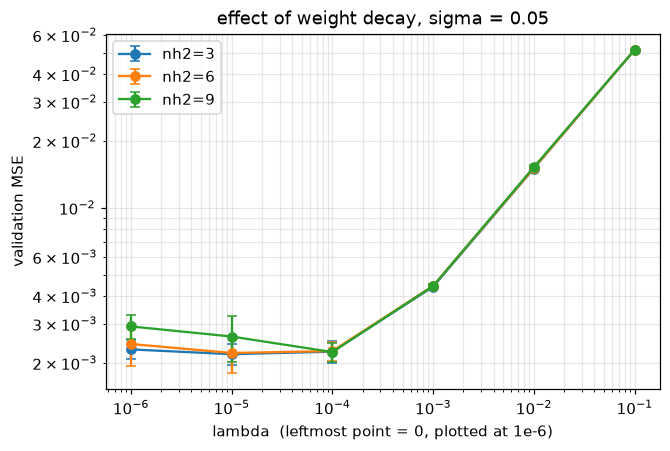

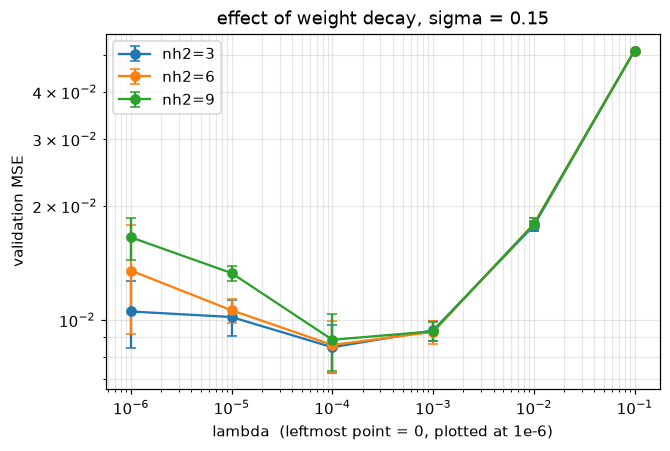

In [12]:
for sigma in (0.0, 0.05, 0.15):
    fig = P.plot_lambda_curves(nrows, sigma)
    P.save(fig, f"06_lambda_sigma{sigma}.png"); plt.show()

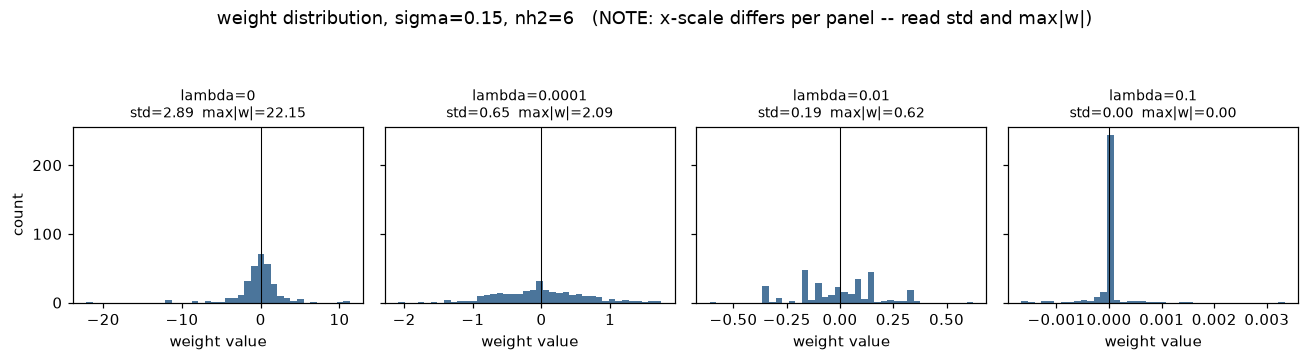

   lambda    std(w)   mean|w|    max|w|
---------------------------------------
        0     2.610     1.695    10.685
    1e-05     1.102     0.906     3.187
   0.0001     0.632     0.504     1.588
    0.001     0.292     0.144     1.072
     0.01     0.185     0.150     0.454
      0.1     0.000     0.000     0.002


In [13]:
# effect of lambda on the WEIGHT DISTRIBUTION
fig = P.plot_weight_distribution(nruns, sigma=0.15, nh2=6,
                                 lambdas=(0.0, 1e-4, 1e-2, 1e-1))
P.save(fig, "07_weight_distribution.png"); plt.show()

print(f"{'lambda':>9} {'std(w)':>9} {'mean|w|':>9} {'max|w|':>9}")
print("-" * 39)
for r in sorted([q for q in nrows if q["sigma"] == 0.15 and q["nh2"] == 6],
                key=lambda q: q["lam"]):
    print(f"{r['lam']:>9g} {r['w_std_mean']:>9.3f} "
          f"{r['w_absmean_mean']:>9.3f} {r['w_absmax_mean']:>9.3f}")

### The $\lambda$–noise interaction

Decompose the expected squared error:

$$\mathbb{E}[(\hat{y}-y)^2] = \text{bias}^2 + \text{variance} + \sigma^2$$

$\sigma^2$ is irreducible. But the **variance** term scales with $\sigma^2$:
more observation noise means the fitted function depends more strongly on which
noise realisation you happened to draw. Regularisation trades bias for variance,
so the optimum sits where the marginal variance reduction equals the marginal
bias increase.

**As $\sigma$ grows, the variance term grows, so the optimal $\lambda$ grows.**
Read the $\lambda^*$ table above down the $\sigma$ axis, and look for the minimum
of each U-curve moving to the right as $\sigma$ increases.

## 4.3 task 5 (non-mandatory) — model selection at $\sigma = 0.09$

Three networks trained **from scratch** on data corrupted with $\sigma = 0.09$:

- **A** — best $(n_{h1} \times n_{h2}, \lambda)$ selected under this noise
- **B** — the task-2 most suitable architecture, $\lambda = 0$
- **C** — the task-2 least suitable architecture, $\lambda = 0$

**Selection uses the validation set.** It is the only block that is neither used
for weight updates nor reserved as the final test. For B and C nothing is being
selected — architecture and $\lambda$ are fixed in advance — so there the
validation set does one job only: driving early stopping.

In [14]:
import model_selection_noise as M

path = f"{RESULTS}/model_selection_noise.json"
if RERUN or not os.path.exists(path):
    sel_best, search = M.select_best(train, val, test)
    comp = M.compare([
        (f"A: selected at sigma={M.SIGMA}", sel_best["nh1"], sel_best["nh2"], sel_best["lam"]),
        ("B: task-2 most suitable, lam=0",  best["nh1"],  best["nh2"],  0.0),
        ("C: task-2 least suitable, lam=0", worst["nh1"], worst["nh2"], 0.0),
    ], train, val, test)
    json.dump({"selected": sel_best, "search": search, "comparison": comp},
              open(path, "w"), indent=1)
else:
    d = json.load(open(path)); sel_best, comp = d["selected"], d["comparison"]

print(f"selected under noise: {sel_best['nh1']}x{sel_best['nh2']}, lambda={sel_best['lam']}\n")
print(M.format_table(comp))

selected under noise: 5x6, lambda=1e-05

                            model   arch   lambda                 val MSE                test MSE
-------------------------------------------------------------------------------------------------
        A: selected at sigma=0.09 5x6       1e-05  3.930e-03+/-4.1e-04     3.723e-03+/-4.9e-04   
   B: task-2 most suitable, lam=0 5x6           0  3.979e-03+/-5.2e-04     3.739e-03+/-5.6e-04   
  C: task-2 least suitable, lam=0 3x4           0  4.242e-03+/-3.6e-04     3.984e-03+/-5.5e-04   


## Summary

Fill in against the numbers printed above when writing the report.

1. **Most / least suitable architecture** — decided on mean validation MSE over
   10 seeds, then confirmed on the test block.
2. **Robustness to initialisation** — the *relative* spread (std/mean) is the
   number to quote; the smallest architecture is both the worst and the least
   reliable.
3. **Convergence is a confound, and we caught it.** At a 10 000-epoch budget the
   grid ranked convergence speed rather than capacity. Small networks need
   roughly 5x more epochs to plateau. Reporting under-converged models as
   "least suitable" would have been a real error.
4. **Clean data barely over-fits.** With at most 73 parameters against 800
   training samples, train ≈ val ≈ test everywhere in the grid. Over-fitting
   only appears once capacity is pushed far past the lab's range (a 64×64 net
   reaches train 8e-6 but val 5.7e-4) or once noise is added — which is exactly
   why task 4 needs noise to make regularisation matter at all.
5. **Weight decay** shrinks the weight distribution towards zero (falling
   `std(w)` and `max|w|`, tails first) and the optimal $\lambda$ increases with
   the noise level, as the bias–variance decomposition predicts.

Reference: `NOTES.md` for the theory, `README.md` for the team decisions.